##### 신문기자 챗봇 만들기
- 랭그래프는 랭체인에 기반하므로 언어모델에서 미리 정의한 도구를 사용할 수 있게 구현할 수 있다. 

In [29]:
from dotenv import load_dotenv
import os

load_dotenv()
api_key = os.getenv('OPENAI_API_KEY')

In [30]:
from langchain_openai import ChatOpenAI

# 모델 초기화
model = ChatOpenAI(model="gpt-5.6-luna", temperature=0.01, reasoning_effort="none")
model.invoke('안녕하세요!')

AIMessage(content='안녕하세요! 무엇을 도와드릴까요?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 14, 'prompt_tokens': 9, 'total_tokens': 23, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5.6-luna', 'system_fingerprint': None, 'id': 'chatcmpl-EXSZndDUpC3rgj1s4pAFrNUUATuK5', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a12644-62de-73a0-b254-da8d2a46f618-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 9, 'output_tokens': 14, 'total_tokens': 23, 'input_token_details': {'audio': 0, 'cache_read': 0, 'cache_creation': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})

In [31]:
from typing import Annotated # annotated는 타입 힌트를 사용할 때 사용하는 함수
from typing_extensions import TypedDict # TypedDict는 딕셔너리 타입을 정의할 때 사용하는 함수

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

class State(TypedDict):
    """
    State 클래스는 TypedDict를 상속받습니다.

    속성:
        messages (Annotated[list[str], add_messages]): 메시지들은 "list" 타입을 가집니다. 
        주석에 있는 'add_messages' 함수는 이 상태 키가 어떻게 업데이트되어야 하는지를 정의합니다.
        (이 경우, 메시지를 덮어쓰는 대신 리스트에 추가합니다)
    """
    messages: Annotated[list[str], add_messages]

# StateGraph 클래스를 사용하여 State 타입의 그래프를 생성합니다.
graph_builder = StateGraph(State) 

- 8장과 10장에서 다루었던 시간을 알려주는 함수와 웹검색을 해주는 함수를 활용.

In [32]:
from langchain_core.tools import tool
from datetime import datetime
import pytz
from ddgs.exceptions import DDGSException
from langchain_community.tools import DuckDuckGoSearchResults
from langchain_community.utilities import DuckDuckGoSearchAPIWrapper

# 도구 함수 정의
@tool
def get_current_time(timezone: str, location: str) -> str:
    """현재 시각을 반환하는 함수."""
    try:
        tz = pytz.timezone(timezone)
        now = datetime.now(tz).strftime("%Y-%m-%d %H:%M:%S")
        result = f'{timezone} ({location}) 현재시각 {now}'
        # print(result)
        return result
    except pytz.UnknownTimeZoneError:
        return f"알 수 없는 타임존: {timezone}"
    
@tool
def get_web_search(query: str, search_period: str='m') -> str:
    """
    웹 검색을 수행하는 함수.

    Args:
        query (str): 검색어
        search_period (str): 검색 기간 (e.g., "w" for past week (default), "m" for past month, "y" for past year, "d" for past day)

    Returns:
        str: 검색 결과
    """
    wrapper = DuckDuckGoSearchAPIWrapper(
        region="kr-kr",
        time=search_period,
    )

    print('\n-------- WEB SEARCH --------')
    print(query)
    print(search_period)

    search = DuckDuckGoSearchResults(
        api_wrapper=wrapper,
        # source="news",
        results_separator=';\n'
    )

    try:
        searched = search.invoke(query)
    except DDGSException as exc:
        return f"DuckDuckGo 검색에 실패했습니다 ({exc}). 검색어를 바꾸거나 잠시 후 다시 시도해 주세요."
    
    for i, result in enumerate(searched.split(';\n')):
        print(f'{i+1}. {result}')
    
    return searched

# 도구 바인딩
tools = [get_current_time, get_web_search]

In [33]:
tools[0].invoke({"timezone": "Asia/Seoul", "location": "서울"})

'Asia/Seoul (서울) 현재시각 2026-10-10 23:42:59'

In [34]:
tools[1].invoke({"query": "랭그래프", "search_period": "m"})


-------- WEB SEARCH --------
랭그래프
m
1. snippet: Ch05-랭그래프 기본 개념 이해하기 Raw 5.2_랭그래프 기본 개념 이해하기.ipynb Learn more about bidirectional Unicode characters { "cells": [ { "cell_type": "markdown", "id": "eaaf264b", "metadata": {}, "source": [ "## 5.2 랭그래프 기본 개념 이해하고 적용하기" ] }, { "cell_type": "code", "execution_count": 1 ..., title: Ch05-랭그래프 기본 개념 이해하기 · GitHub, link: https://gist.github.com/hoconoco/e9356799b22c50f0ef4be488753d32f7?short_path=3ca53c0
2. snippet: AWS의 스트랜즈 (Strands Agents), LangChain 진영의 랭그래프 (LangGraph), 역할 기반 팀 구성이 특징인 크루AI (CrewAI)는 모두 무료로 쓸 수 있어요. 하지만 설계 철학이 완전히 달라서, 잘못 고르면 나중에 통째로 다시 짓게 될 수도 있어요., title: 오픈소스 AI 에이전트 프레임워크 비교: 스트랜즈·랭그래프·크루AI 선택 가이드 (2026년) | Eduinfom, link: https://eduinfom.com/invest/23051/
3. snippet: 📘 원본: 《LangGraph 가이드북 - 에이전트 RAG with 랭그래프 [ver 1.0+]》 · 1-3-4-3. 조건부 엣지 (Conditional Edges) 🤔 이런 질문에서 시작합니다 사용자의 질문이 단순한 인사인지, 아니면 복잡한 명령인지에 따라 AI의 대응 방식이 달라져야 한다면 어떻게 해야 할까요? 모든 경우의 수를 하나의 경로로 ..., title: [LangGraph] 상태에 따라 경로를 바꾸는 조건부 엣지 활용법, link: htt

'snippet: Ch05-랭그래프 기본 개념 이해하기 Raw 5.2_랭그래프 기본 개념 이해하기.ipynb Learn more about bidirectional Unicode characters { "cells": [ { "cell_type": "markdown", "id": "eaaf264b", "metadata": {}, "source": [ "## 5.2 랭그래프 기본 개념 이해하고 적용하기" ] }, { "cell_type": "code", "execution_count": 1 ..., title: Ch05-랭그래프 기본 개념 이해하기 · GitHub, link: https://gist.github.com/hoconoco/e9356799b22c50f0ef4be488753d32f7?short_path=3ca53c0;\nsnippet: AWS의 스트랜즈 (Strands Agents), LangChain 진영의 랭그래프 (LangGraph), 역할 기반 팀 구성이 특징인 크루AI (CrewAI)는 모두 무료로 쓸 수 있어요. 하지만 설계 철학이 완전히 달라서, 잘못 고르면 나중에 통째로 다시 짓게 될 수도 있어요., title: 오픈소스 AI 에이전트 프레임워크 비교: 스트랜즈·랭그래프·크루AI 선택 가이드 (2026년) | Eduinfom, link: https://eduinfom.com/invest/23051/;\nsnippet: 📘 원본: 《LangGraph 가이드북 - 에이전트 RAG with 랭그래프 [ver 1.0+]》 · 1-3-4-3. 조건부 엣지 (Conditional Edges) 🤔 이런 질문에서 시작합니다 사용자의 질문이 단순한 인사인지, 아니면 복잡한 명령인지에 따라 AI의 대응 방식이 달라져야 한다면 어떻게 해야 할까요? 모든 경우의 수를 하나의 경로로 ..., title: [LangGraph] 상태에 따라 경로를 바꾸는 조건부 엣지 활용법, link: https://wikidocs.net/blog/@pandas_studio/329

In [35]:
for tool in tools:
    print(tool.name, tool)

get_current_time name='get_current_time' description='현재 시각을 반환하는 함수.' args_schema=<class 'langchain_core.utils.pydantic.get_current_time'> func=<function get_current_time at 0x000002CB673EA200>
get_web_search name='get_web_search' description='웹 검색을 수행하는 함수.\n\nArgs:\n    query (str): 검색어\n    search_period (str): 검색 기간 (e.g., "w" for past week (default), "m" for past month, "y" for past year, "d" for past day)\n\nReturns:\n    str: 검색 결과' args_schema=<class 'langchain_core.utils.pydantic.get_web_search'> func=<function get_web_search at 0x000002CB673B1580>


- 언어 모델에 도구 연결하기

In [36]:
model_with_tools = model.bind_tools(tools) # GPT 언어모델에 도구 연결

def generate(state: State):
    """
    주어진 상태를 기반으로 챗봇의 응답 메시지를 생성합니다.

    매개변수:
    state (State): 현재 대화 상태를 나타내는 객체로, 이전 메시지들이 포함되어 있습니다.

    반환값:
    dict: 모델이 생성한 응답 메시지를 포함하는 딕셔너리. 
          형식은 {"messages": [응답 메시지]}입니다.
    """
    return {"messages": model_with_tools.invoke(state["messages"])}

graph_builder.add_node("generate", generate)

- 랭그래프에서 도구를 독립된 노드에서 실행하기

In [37]:
import json
from langchain_core.messages import ToolMessage

class BasicToolNode:
    """
    도구를 실행하는 노드 클래스입니다. 마지막 AIMessage에서 요청된 도구를 실행합니다.
    Attributes:
        tools_by_name (dict): 도구 이름을 키로 하고 도구 객체를 값으로 가지는 사전입니다.
    Methods:
        __init__(tools: list): 도구 객체들의 리스트를 받아서 초기화합니다.
        __call__(inputs: dict): 입력 메시지를 받아서 도구를 실행하고 결과 메시지를 반환합니다.
    """
    """A node that runs the tools requested in the last AIMessage."""

    def __init__(self, tools: list) -> None:    # ①
        self.tools_by_name = {tool.name: tool for tool in tools}

    def __call__(self, inputs: dict):    # ②
        if messages := inputs.get("messages", []):
            # inputs에 messages가 있으면 messages를 가져오고 없으면 빈 리스트를 가져옵니다.
            message = messages[-1]
        else:
            raise ValueError("No message found in input")
        outputs = []
        for tool_call in message.tool_calls:    # ③
            tool_result = self.tools_by_name[tool_call["name"]].invoke(
                tool_call["args"]
            )
            outputs.append(
                ToolMessage(
                    content=json.dumps(tool_result),
                    name=tool_call["name"],
                    tool_call_id=tool_call["id"],
                )
            )
        return {"messages": messages + outputs}

tool_node = BasicToolNode(tools=tools)
graph_builder.add_node("tools", tool_node)

##### 라우터 설정하기
- ai 에이전트가 랭그래프 내에서 상황에 맞게 스스로 다음 경로를 선택해야 할때 라우터(router)를 활용.
- 조건에 따라 활성화/비활성화되는 조건부 엣지(conditional edge)를 사용.

In [38]:
def route_tools(state: State):
    """
    마지막 메시지에 도구 호출이 있는 경우 ToolNode로 라우팅하고,
    그렇지 않은 경우 끝으로 라우팅하기 위해 conditional_edge에서 사용합니다.
    """
    if isinstance(state, list):
        ai_message = state[-1]
    elif messages := state.get("messages", []):
        ai_message = messages[-1]
    else:
        raise ValueError(f"tool_edge 입력 상태에서 메시지를 찾을 수 없습니다: {state}")
    if hasattr(ai_message, "tool_calls") and len(ai_message.tool_calls) > 0:
        return "tools"
    return END

graph_builder.add_edge(START, "generate")

graph_builder.add_conditional_edges(
    "generate",
    route_tools,
    {"tools": "tools", END: END},
)
# 도구가 호출될 때마다 다음 단계를 결정하기 위해 챗봇으로 돌아갑니다.
graph_builder.add_edge("tools", "generate")
graph = graph_builder.compile()

- 실행 그래프 시각화

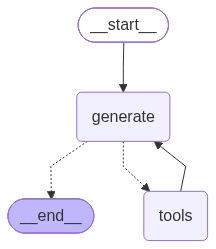

In [39]:
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

##### TESTING

In [40]:
from langchain_core.messages import AIMessageChunk, HumanMessage

inputs = [HumanMessage(content="지금 서울 몇시야?")]

gathered = None

for msg, metadata in graph.stream({"messages": inputs}, stream_mode="messages"):
    if isinstance(msg, AIMessageChunk):
        print(msg.content, end='')

        if gathered is None:
            gathered = msg
        else:
            gathered = gathered + msg

from rich.pretty import pprint
pprint(gathered)

서울은 지금 **2026년 10월 10일 오후 11시 43분**이에요.

AIMessageChunk(
│   content='서울은 지금 **2026년 10월 10일 오후 11시 43분**이에요.',
│   additional_kwargs={},
│   response_metadata={
│   │   'model_provider': 'openai',
│   │   'finish_reason': 'tool_callsstop',
│   │   'model_name': 'gpt-5.6-lunagpt-5.6-luna',
│   │   'service_tier': 'defaultdefault'
│   },
│   id='lc_run--01a12644-79db-7682-ae01-11e1ba359ef6',
│   tool_calls=[
│   │   {
│   │   │   'name': 'get_current_time',
│   │   │   'args': {'timezone': 'Asia/Seoul', 'location': '서울'},
│   │   │   'id': 'call_ZgJUzIirieBwQzCwxpG7VRNs',
│   │   │   'type': 'tool_call'
│   │   }
│   ],
│   invalid_tool_calls=[],
│   usage_metadata={
│   │   'input_tokens': 537,
│   │   'output_tokens': 52,
│   │   'total_tokens': 589,
│   │   'input_token_details': {'audio': 0, 'cache_creation': 0, 'cache_read': 0},
│   │   'output_token_details': {'audio': 0, 'reasoning': 0}
│   },
│   tool_call_chunks=[
│   │   {
│   │   │   'name': 'get_current_time',
│   │   │   'args': '{"timezone":"Asia/Seoul","location":"서울"}',
│   │   │   'id': 'call_ZgJUzIirieBwQzCwxpG7VRNs',
│   │   │   'index': 0,
│   │   │   'type': 'tool_call_chunk'
│   │   }
│   ],
│   chunk_position='last'
)

- inputs에 HumanMessage 대신 SystemMessage 사용하여 언어 모델에게 역할을 지시.
- f-string에 기사 주제를 사용하여 {about} 을 받아오는 형태로 프롬프트 입력.

In [41]:
from langchain_core.messages import AIMessageChunk, SystemMessage

about = "여수 섬 박람회 문제"

inputs = [SystemMessage(content=f"""
너는 신문기자이다. 
최근 {about}에 대해 비판하는 심층 분석 기사를 쓰려고 한다.  

- 최근 어떤 이슈가 있는지 검색하고, 사람들이 제일 관심있어 할만한 주제를 선정하고, 왜 선정했는지 말해줘. 
- 그 내용으로 원고를 작성하기 위한 목차를 만들고, 목차 내용을 채우기 위해 추가로 검색할 내용을 리스트로 정리해봐. 
- 검색할 리스트를 토대로 재검색을 한다. 
- 목차에 있는 내용을 작성하기 위해 더 검색이 필요한 정보가 있는지 확인하고, 있다면 추가로 검색해라.
- 검색된 결과에 원하는 정보를 찾지 못했다면 다른 검색어로 재검색해도 좋다. 

더 이상 검색할 내용이 없다면, 조선일보 신문 기사 형식으로 최종 기사를 작성하라.
제목, 부제, 리드문, 본문 의 구성으로 작성하라. 본문 내용은 심층 분석 기사에 맞게 구체적이고 깊이 있게 작성해야 한다. 
    
""")]

for msg, metadata in graph.stream({"messages": inputs}, stream_mode="messages"):
    if isinstance(msg, AIMessageChunk):
        print(msg.content, end='')


-------- WEB SEARCH --------
여수 섬 박람회 최근 논란 문제 2026
y

-------- WEB SEARCH --------
2026 여수세계섬박람회 논란
y
1. snippet: 1 day ago · [이슈] "2차 잼버리 사태 예고" 여수 섬박람회 준비 부실 논란/2026년 4월 7일 (화)/KBS 2026년 3월, 준비 기간이 3년이 넘었음에도 개막 5개월 전까지 청소가 안 되어 있는 것은 기본이고, 주 행사장은 건설되지도 않은 등 3년 전 잼버리 사태 와 유사한 문제점들이 적발 ..., title: 2026 여수세계섬박람회/논란 및 문제점 - 나무위키, link: https://namu.wiki/w/2026+여수세계섬박람회/논란+및+문제점
2. snippet: Jun 20, 2026 · 이번 논란을 하나씩 정리해보겠습니다. 개막 초기부터 나온 ‘볼거리 부족’ 지적 2026 여수세계섬박람회가 문을 연 뒤 가장 먼저 나온 반응 중 하나는 콘텐츠에 대한 아쉬움이었습니다., title: 2026 여수세계섬박람회, 1800억 어디에 썼나? 예산·입장료·볼거리 논..., link: https://blog.naver.com/qkrgnsrms/224410354996
3. snippet: Sep 30, 2026 · 여수의 대표적인 섬인 거문도, 낭도, 송도, 연도, 대횡간도 등 '가고 싶은 섬 사업지'가 연계될 것으로 추정되었다. 2024년부터 본격적으로 사업이 시작되었는데, 사업비는 당초 240억 원으로 신청하였으나 최종 212.1억 원으로 조정되었다. 2024년 1월에는 섬박람회를 ..., title: 2026 여수세계섬박람회 - 나무위키, link: https://namu.wiki/w/2026+여수세계섬박람회
4. snippet: Sep 8, 2026 · 오늘은 여수세계섬박람회 2026 후기 논란부터 입장료, 볼거리, 운영시간, 방문 전 알아두면 좋은 정보까지 한 번에 정리해볼게요. 여수세계섬박람회 2026 언제까지 하나요? 먼저 가장 